# Budget follow-up: model comparison and fresh Beer Games

**Open this notebook to review the follow-up already run by the assistant.** No API calls occur with the default `RUN_API = False`.

The fixed development comparison used GPT-5.4 nano, GPT-5.4 mini and GPT-5.6 Luna with original/clarified instructions. Selection used factual comprehension, valid replies and price; no H1/H2 results were used. The selected Luna model did not hit a 96-token cap, so the fresh calibration uses **32 / 240 / 480 tokens**. Games start only if that calibration passes. The follow-up plans **two chains per condition, four role agents per chain**.

This is a feasibility pilot. Earlier results remain separate; more trials or a more expensive model cannot guarantee statistical significance.

**Completed results:** 4 chains, 16 role agents, 576 decisions; no zero orders; orders ranged from 4 to 12. Short-chain costs were **852 and 240**, versus **156 and 156** with adequate tokens. These two pairs support the predicted direction of H2 descriptively, without statistical confirmation. **H1 remains unidentified:** adequate agents copied incoming demand, so the trajectories do not identify a separate supply-line beta.

New follow-up estimated spending/reservations: **$0.9762**. Known current-study total including the four earlier runs: **$1.3483**. These figures include a conservative Luna cache-write allowance and are not the account balance.

In [1]:
from pathlib import Path
import sys, json, os, getpass
import pandas as pd
from IPython.display import display, HTML, Image
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for parent in candidates for p in (parent, parent / "Project/beer_game_experiment")
             if (p / "scripts/run_budget_followup.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the beer_game_experiment project.")
sys.path.insert(0, str(ROOT / "scripts"))
import run_budget_followup as campaign
from budget_model_screen import BudgetStop
SCREEN_DIR = ROOT / "data/development/model_screen_20261005"
REPORT_DIR = ROOT / "reports/budget_followup_20261005"
print("Project:", ROOT)

Project: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment


## 1. Spending and progress — safe to run repeatedly

Costs are calculated/reserved from saved requests, not an account balance. The earlier four current-study runs cost approximately $0.3720. The planned stage limits sum to at most $1.50 for the selected low-cost model, including the separate $0.03 calibration-metadata recheck, leaving a margin under the approximately $3 total budget. Luna input charges include a conservative cache-write allowance. The archive contains older experiments outside this subtotal.

In [2]:
from html import escape
status = campaign.totals()
display(pd.DataFrame(status["stages"]))
print(f"New follow-up estimated charges/reservations: ${status['new_spend_usd']:.4f}")
print(f"Known current-study total: ${status['known_current_study_total_usd']:.4f}")
for row in status["stages"]:
    total = row["done"] + row["left"]
    display(HTML(f"<b>{escape(row['stage'])}: {escape(row['phase'])}</b> "
                 f"<progress value='{row['done']}' max='{max(1,total)}'></progress> "
                 f"{row['done']} done; {row['left']} left"))

,stage,cost_usd,phase,done,left
0,Model screen,0.256198,complete,300,0
1,Calibration,0.045750,complete,144,0
2,Games,0.666727,complete,1168,0
3,Calibration metadata recheck,0.007561,complete,24,0


New follow-up estimated charges/reservations: $0.9762
Known current-study total: $1.3483


## 2. Resume only if needed

Leave `RUN_API = False` to review saved results. Setting it to `True` resumes the frozen follow-up; completed phases are loaded and are not purchased again. The local spending limits cannot be increased here. If a phase stopped because its allowance or calibration failed, inspect the saved diagnosis first.

The key is requested in a hidden input box, used only in memory and excluded from result files.

In [3]:
RUN_API = False
if not RUN_API:
    print("Review only: no paid API calls.")
else:
    record = campaign.freeze()
    if record.get("status") == "complete":
        print("Already complete. Saved results loaded; no paid API calls.")
    else:
        from openai import AsyncOpenAI
        _api_key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
        if not _api_key.strip():
            raise ValueError("No API key entered.")
        _client = AsyncOpenAI(api_key=_api_key.strip(), max_retries=0, timeout=90.)
        del _api_key
        try:
            await campaign.run(_client)
        except BudgetStop as exc:
            print("Stopped:", str(exc))
        finally:
            await _client.close()
            del _client
        display(pd.DataFrame(campaign.totals()["stages"]))

Review only: no paid API calls.


## 3. Model comparison and calibration

The comparison includes states selected from the previous failure, so it is a development check rather than an independent test of generalization. “Eligible” does not establish the hypotheses. Every candidate response remains saved.

In [4]:
if (SCREEN_DIR / "summary.csv").exists():
    display(pd.read_csv(SCREEN_DIR / "summary.csv"))
record = json.loads(campaign.CAMPAIGN.read_text()) if campaign.CAMPAIGN.exists() else {}
print("Selected model:", record.get("selected", {}).get("model", "not selected"))
if record.get("calibration_dir"):
    calibration_dir = Path(record["calibration_dir"])
    if (calibration_dir / "calibration_summary.csv").exists():
        display(pd.read_csv(calibration_dir / "calibration_summary.csv"))
        print(json.loads((calibration_dir / "calibration_recommendation.json").read_text()))

,model,prompt,eligible,quizzes_correct,valid_decisions,adequate_factory_shortage_zeros,short_factory_shortage_zeros,short_mean_tokens,adequate_mean_tokens,short_truncation,adequate_truncation
0,gpt-5.4-nano-2026-03-17,original,False,0,24,1,2,96.000000,164.416667,1.000000,0.000000
1,gpt-5.4-nano-2026-03-17,clarified,True,2,24,0,1,96.000000,207.250000,1.000000,0.166667
2,gpt-5.4-mini-2026-03-17,original,False,2,24,1,1,70.416667,115.833333,0.083333,0.000000
3,gpt-5.4-mini-2026-03-17,clarified,True,2,24,0,1,84.833333,126.416667,0.250000,0.000000
4,gpt-5.6-luna,original,True,2,24,0,0,49.083333,94.250000,0.000000,0.000000
5,gpt-5.6-luna,clarified,True,2,24,0,0,52.916667,92.750000,0.000000,0.000000


Selected model: gpt-5.6-luna


,screen,mean_tokens,truncated_fraction,mean_order
0,adequate,95.208333,0.000000,40.333333
1,benchmark,150.833333,0.000000,38.666667
2,short,31.375000,0.708333,32.000000


{'short_tokens': 32, 'adequate_tokens': 240, 'benchmark_tokens': 480, 'median_absolute_adequate_benchmark_order_difference': 0.0, 'manipulation_screen_passed': True, 'mode': 'api', 'method': 'Prospectively fixed caps; fresh mixed-scale feasibility states; no reference percentiles'}


## 4. Game results and report

Costs are game cost units, separate from API dollars. Beta measures fitted supply-line weight. Unusable fits remain visible. With two independent chain pairs this is a pilot; weekly orders are not independent experimental participants.

Group Outcomes


,group_id,block,condition,agent_phase_cost,continuation_cost,total_scored_cost,group_beta,usable_role_betas,customer_fulfillment,retailer_backlog_weeks,terminal_inventory,terminal_backlog
0,b000_adequate,0,adequate,156.0,0.0,156.0,NaN,0,1.000000,0,0,0
1,b000_short,0,short,684.0,168.0,852.0,NaN,3,0.986842,30,12,8
2,b001_adequate,1,adequate,156.0,0.0,156.0,NaN,0,1.000000,0,0,0
3,b001_short,1,short,216.0,24.0,240.0,NaN,0,1.000000,0,4,0


Manipulation Check


,condition,mean_preparation_tokens,median_preparation_tokens,truncated_fraction,mean_final_tokens,zero_rate,max_order
0,adequate,90.763889,91.0,0.000000,39.0,0.0,8
1,short,31.684028,32.0,0.788194,39.0,0.0,12


Beta Fits


,group_id,role,condition,block,positive_orders,theta,alpha,beta,target,rmse,r2,jac_condition,usable,fit_flag,n,order_limit,cap_hit_rate
0,b000_adequate,distributor,adequate,0,36,0.999990,0.000008,1.503842,24.030473,3.055298e-06,1.000000,1.795868e+01,False,weak_inventory_response;parameter_boundary,36,NaN,0.0
1,b000_adequate,factory,adequate,0,36,0.999996,0.000003,1.504089,24.033359,1.204700e-06,1.000000,1.474598e+01,False,weak_inventory_response;parameter_boundary,36,NaN,0.0
2,b000_adequate,retailer,adequate,0,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,insufficient_variation,36,NaN,0.0
3,b000_adequate,wholesaler,adequate,0,36,0.999995,0.000004,1.503758,24.030045,1.624525e-06,1.000000,2.531051e+01,False,weak_inventory_response;parameter_boundary,36,NaN,0.0
4,b000_short,distributor,short,0,36,0.227075,0.633571,0.982008,19.821694,4.701595e-01,0.915542,1.450928e+01,True,ok,36,NaN,0.0
5,b000_short,factory,short,0,36,0.164180,0.485092,0.600181,17.558881,4.088624e-01,0.958078,1.304046e+01,True,ok,36,NaN,0.0
6,b000_short,retailer,short,0,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,insufficient_variation,36,NaN,0.0
7,b000_short,wholesaler,short,0,36,0.346509,0.231179,0.887968,10.645744,7.661159e-01,0.660417,1.528078e+01,True,ok,36,NaN,0.0
8,b001_adequate,distributor,adequate,1,36,0.999990,0.000008,1.503842,24.030473,3.055298e-06,1.000000,1.795868e+01,False,weak_inventory_response;parameter_boundary,36,NaN,0.0
9,b001_adequate,factory,adequate,1,36,0.999996,0.000003,1.504089,24.033359,1.204700e-06,1.000000,1.474598e+01,False,weak_inventory_response;parameter_boundary,36,NaN,0.0


Hypotheses


,hypothesis,outcome,estimate,complete_pairs,predicted_direction,p_raw,status,p_holm
0,H1,group_beta,NaN,0,short minus adequate < 0,NaN,"withheld: offline, fewer than 8 pairs, incompl...",NaN
1,H2,total_scored_cost,390.0,2,short minus adequate > 0,NaN,"withheld: offline, fewer than 8 pairs, incompl...",NaN


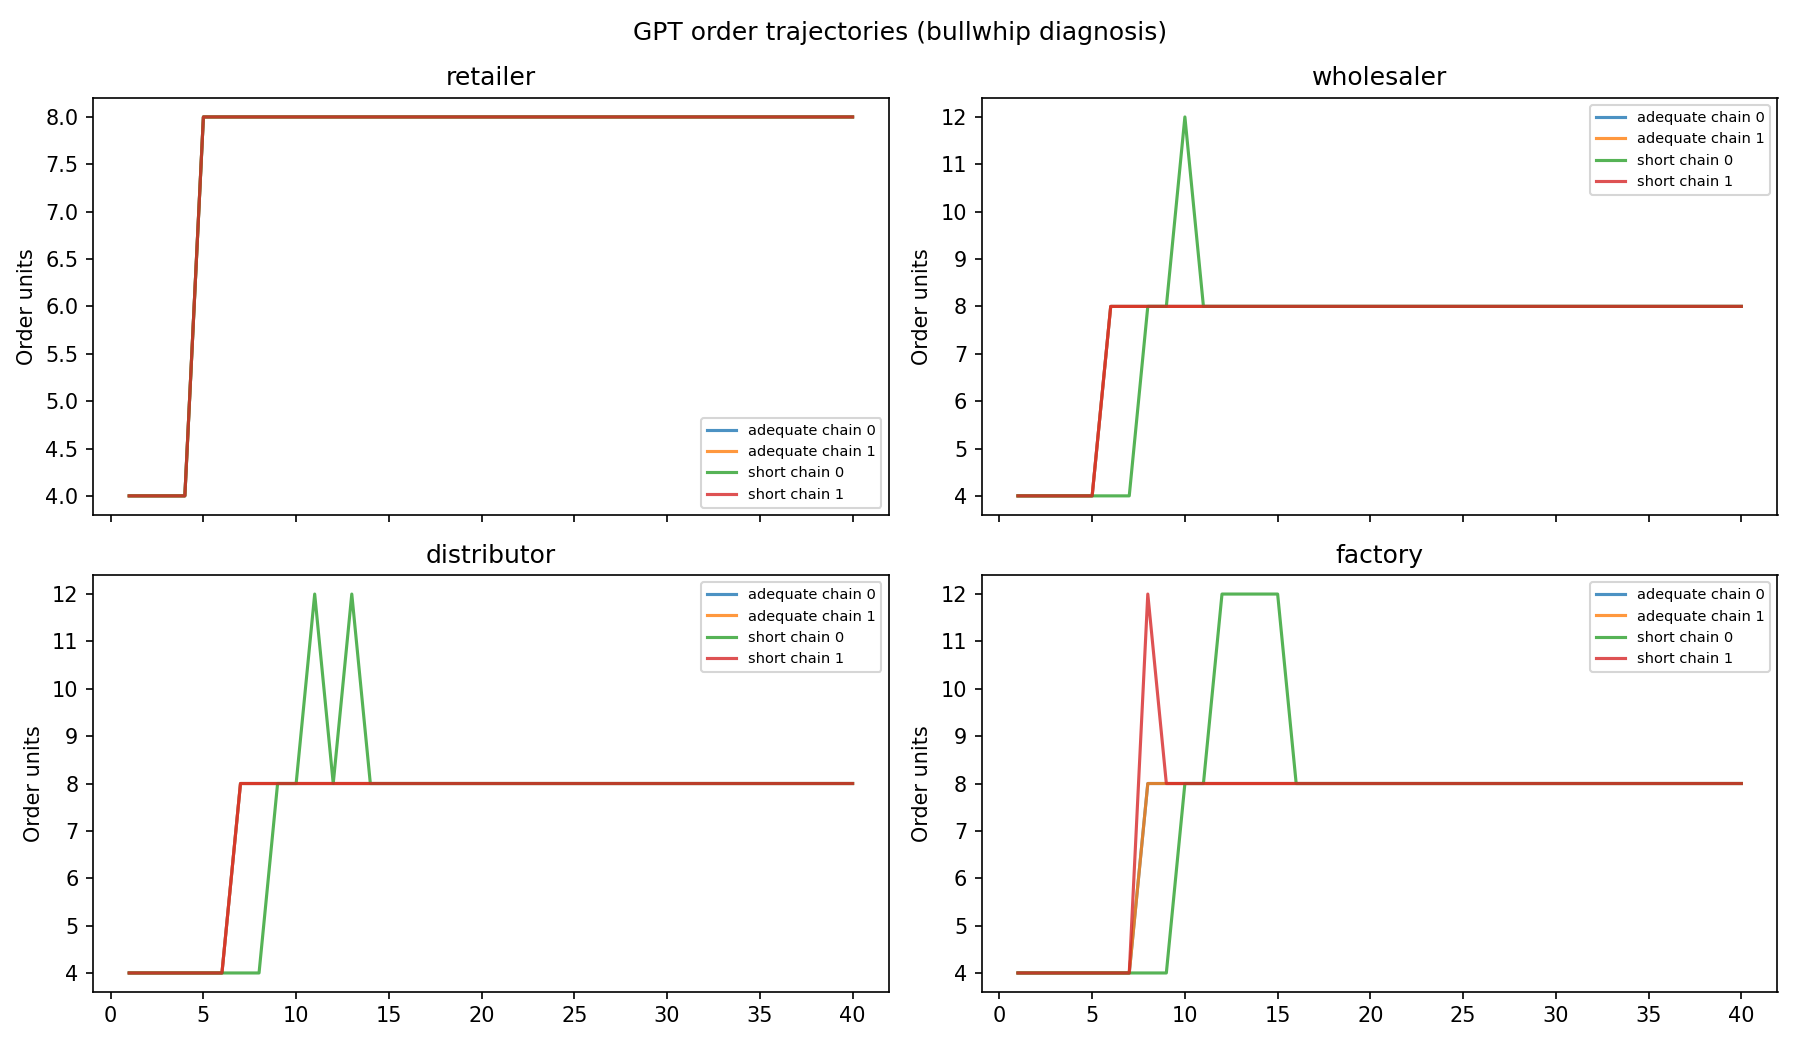

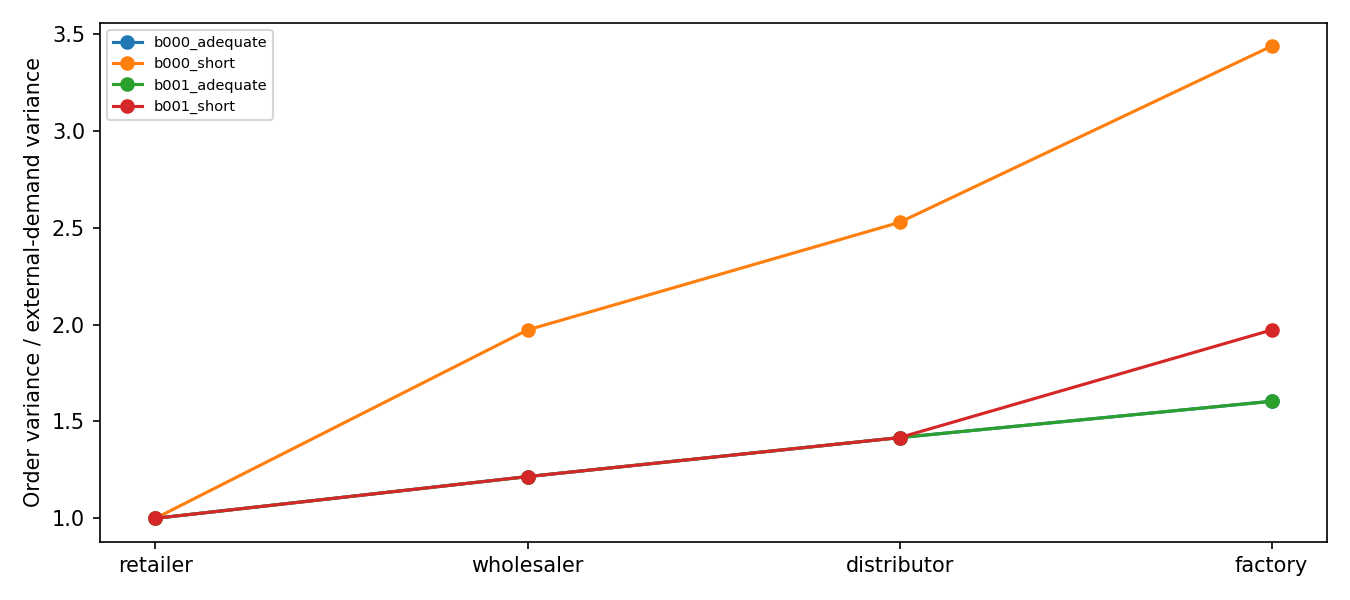

Report file: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/reports/budget_followup_20261005/Budget_Followup_Report.docx
Report file: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/reports/budget_followup_20261005/DETAILS.xlsx
Original pilot report: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/reports/pilot_02_game_api_8236a9c840b29d36/Pilot_Report.docx


In [5]:
if record.get("game_dir"):
    game_dir = Path(record["game_dir"])
    for name in ("group_outcomes", "manipulation_check", "beta_fits", "hypotheses"):
        if (game_dir / f"{name}.csv").exists():
            print(name.replace("_", " ").title())
            display(pd.read_csv(game_dir / f"{name}.csv"))
    for name in ("order_trajectories.png", "bullwhip.png"):
        if (game_dir / name).exists():
            display(Image(filename=str(game_dir / name)))
else:
    print("No game results yet; calibration must pass first.")
for path in (REPORT_DIR / "Budget_Followup_Report.docx", REPORT_DIR / "DETAILS.xlsx"):
    if path.exists():
        print("Report file:", path)
print("Original pilot report:", ROOT / "reports/pilot_02_game_api_8236a9c840b29d36/Pilot_Report.docx")